At this point, you know how to prepare the input text for training LLMs by splitting
text into individual word and subword tokens, which can be encoded into vector rep-
resentations, embeddings, for the LLM.
Now, we will look at an integral part of the LLM architecture itself, attention
mechanisms.
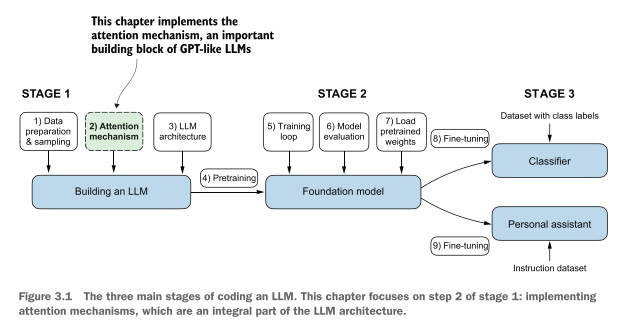
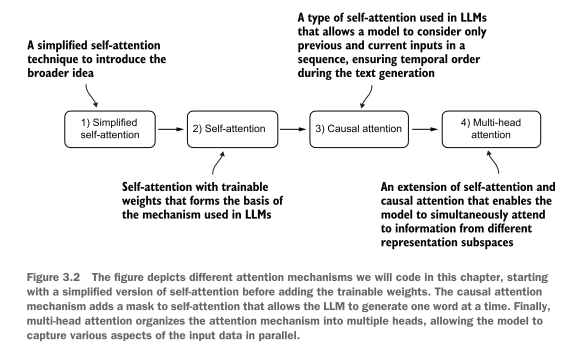

## The problem with modeling long sequences

Before we dive into the self-attention mechanism at the heart of LLMs, let’s consider
the problem with pre-LLM architectures that do not include attention mechanisms.
Suppose we want to develop a language translation model that translates text from
one language into another.
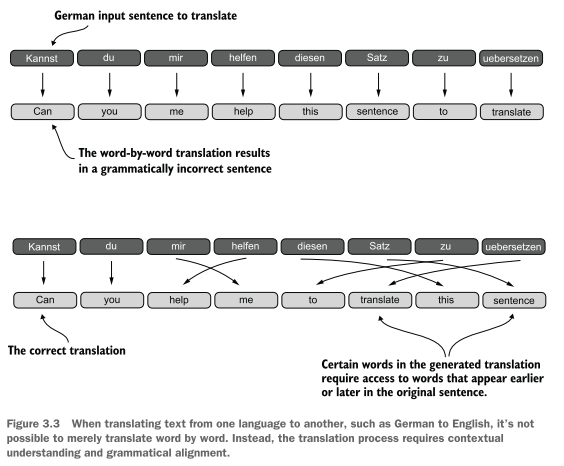

To address this problem, it is common to use a deep neural network with two submod-
ules, an encoder and a decoder. The job of the encoder is to first read in and process the
entire text, and the decoder then produces the translated text.
Before the advent of transformers, recurrent neural networks (RNNs) were the most
popular encoder–decoder architecture for language translation. An RNN is a type of
neural network where outputs from previous steps are fed as inputs to the current step, making them well-suited for sequential data like text.

In an encoder–decoder RNN, the input text is fed into the encoder, which pro-
cesses it sequentially. The encoder updates its hidden state (the internal values at the
hidden layers) at each step, trying to capture the entire meaning of the input sen-
tence in the final hidden state, as illustrated in figure 3.4. The decoder then takes this
final hidden state to start generating the translated sentence, one word at a time. It
also updates its hidden state at each step, which is supposed to carry the context nec-
essary for the next-word prediction.

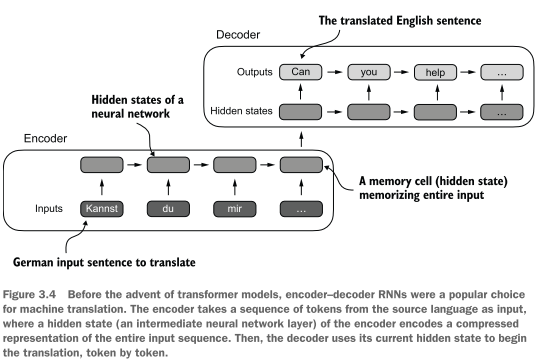

The big limitation of encoder–decoder RNNs is that the RNN can’t directly access
earlier hidden states from the encoder during the decoding phase. Consequently, it
relies solely on the current hidden state, which encapsulates all relevant information.
This can lead to a loss of context, especially in complex sentences where dependen-
cies might span long distances.

## Capturing data dependencies with Attention Mechanisms

Hence, researchers developed the Bahdanau attention mechanism for RNNs in
2014 (named after the first author of the respective paper; for more information, see
appendix B), which modifies the encoder–decoder RNN such that the decoder can
selectively access different parts of the input sequence at each decoding step

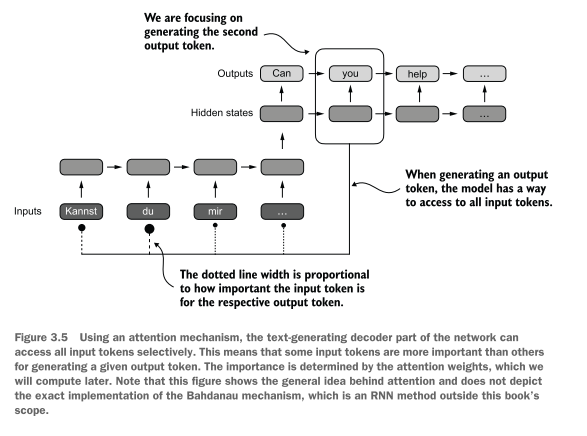

Self-attention is a mechanism that allows each position in the input sequence to
consider the relevancy of, or “attend to,” all other positions in the same sequence
when computing the representation of a sequence. Self-attention is a key component
of contemporary LLMs based on the transformer architecture, such as the GPT series.
This chapter focuses on coding and understanding this self-attention mechanism
used in GPT-like models.

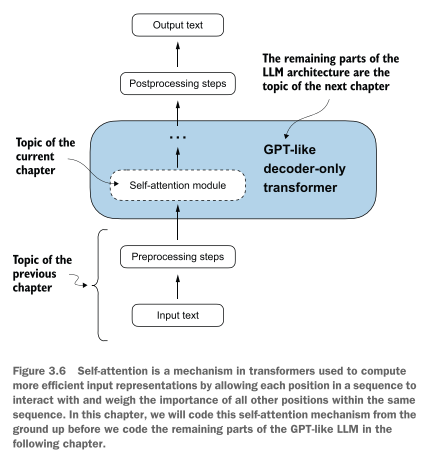

## Attending to different parts of the input with Self-Attention

Self-attention serves as the cornerstone of every LLM
based on the transformer architecture. This topic may require a lot of focus and atten-
tion (no pun intended), but once you grasp its fundamentals, you will have con-
quered one of the toughest aspects of this book and LLM implementation in general

> The “self” in self-attention
In self-attention, the “self” refers to the mechanism’s ability to compute attention
weights by relating different positions within a single input sequence. It assesses and
learns the relationships and dependencies between various parts of the input itself,
such as words in a sentence or pixels in an image.

### A simple self-attention mechanism without trainable weights

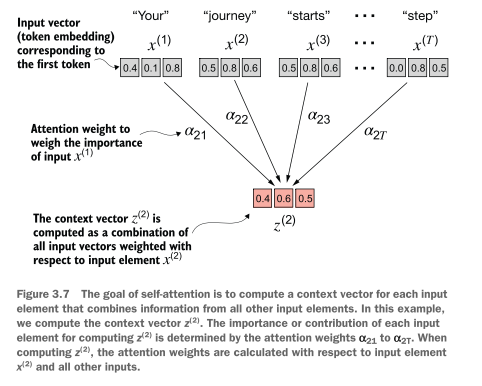

For example, consider an input text like “Your journey starts with one step.” In this
case, each element of the sequence, such as x(1), corresponds to a d-dimensional
embedding vector representing a specific token, like “Your.” Figure 3.7 shows these
input vectors as three-dimensional embeddings.

In self-attention, our goal is to calculate context vectors z(i) for each element x(i)
in the input sequence. A context vector can be interpreted as an enriched embedding
vector.

Context vectors play a crucial role in self-attention. Their purpose is to create
enriched representations of each element in an input sequence (like a sentence)
by incorporating information from all other elements in the sequence (figure 3.7).
This is essential in LLMs, which need to understand the relationship and relevance
of words in a sentence to each other. Later, we will add trainable weights that help
an LLM learn to construct these context vectors so that they are relevant for the
LLM to generate the next token. But first, let’s implement a simplified self-atten-
tion mechanism to compute these weights and the resulting context vector one
step at a time.

In [1]:
import torch
inputs = torch.tensor(
    [[0.43, 0.15, 0.89], # Your
    [0.55, 0.87, 0.66], # journey
    [0.57, 0.85, 0.64], # starts
    [0.22, 0.58, 0.33], # with
    [0.77, 0.25, 0.10], # one
    [0.05, 0.80, 0.55]] # step
)

The first step of implementing self-attention is to compute the intermediate values ω,
referred to as attention scores, as illustrated in figure 3.8. Due to spatial constraints,
the figure displays the values of the preceding inputs tensor in a truncated version

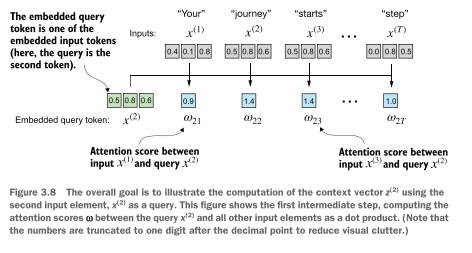

In [2]:
query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


Figure 3.8 illustrates how we calculate the intermediate attention scores between the
query token and each input token. We determine these scores by computing the dot
product of the query, x(2), with every other input token:

>A dot product is essentially a concise way of multiplying two vectors element-wise and
then summing the products, which can be demonstrated as follows

In [3]:
res = 0.
for idx, element in enumerate(inputs[0]):
    res += inputs[0][idx] * query[idx]
print(res)
print(torch.dot(inputs[0], query))

tensor(0.9544)
tensor(0.9544)


The output confirms that the sum of the element-wise multiplication gives the same
results as the dot product

we normalize each of the attention scores we
computed previously. The main goal behind the normalization is to obtain attention
weights that sum up to 1. This normalization is a convention that is useful for interpre-
tation and maintaining training stability in an LLM.

In [4]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
print("Attention Weights: ", attn_weights_2_tmp)
print("Sum: ", attn_weights_2_tmp.sum())

Attention Weights:  tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum:  tensor(1.0000)


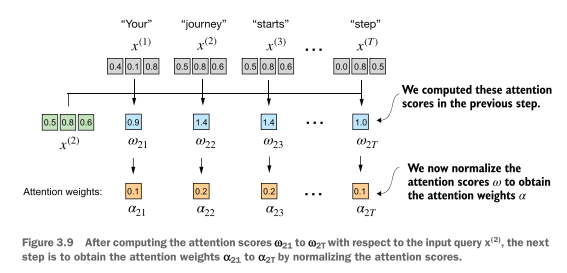

it’s more common and advisable to use the softmax function for normalization. This approach is better at managing extreme values and offers more favorable gradient properties during training.

In [5]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_weights_2_naive = softmax_naive(attn_scores_2)
print("Attention weights:", attn_weights_2_naive)
print("Sum:", attn_weights_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


Now that we have computed the normalized attention weights, we are ready for the
final step, calculating the context vector z(2) by multiplying the
embedded input tokens, x(i), with the corresponding attention weights and then sum-
ming the resulting vectors. Thus, context vector z(2) is the weighted sum of all input vec-
tors, obtained by multiplying each input vector by its corresponding attention weight:

In [6]:
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [7]:
query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i,x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i]*x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


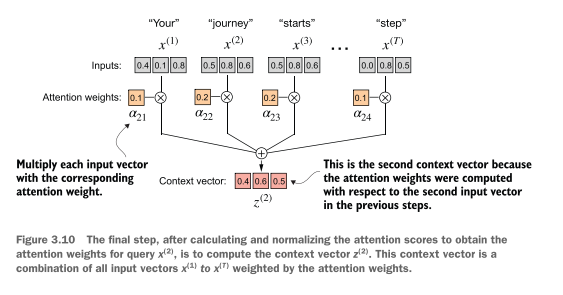

### Computing attention weights for all input tokens

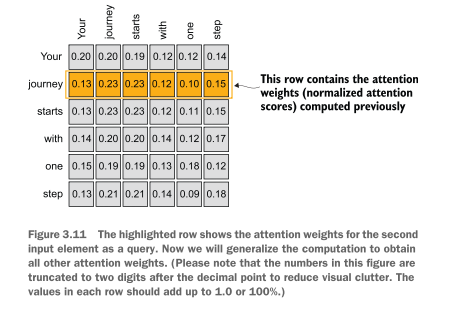

We follow the same three steps as before, except that we make a few
modifications in the code to compute all context vectors instead of only the second
one, z(2)

In [8]:
attn_scores = torch.empty(6,6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


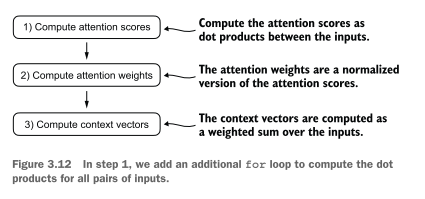

Each element in the tensor represents an attention score between each pair of inputs,
as we saw in figure 3.11. Note that the values in that figure are normalized, which is
why they differ from the unnormalized attention scores in the preceding tensor. We
will take care of the normalization later.

When computing the preceding attention score tensor, we used for loops in
Python. However, for loops are generally slow, and we can achieve the same results
using matrix multiplication:

In [9]:
attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [10]:
# We normalize each row so that the values in each row sum to 1
attn_weights = torch.softmax(attn_scores, dim = -1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In the context of using PyTorch, the dim parameter in functions like torch.softmax
specifies the dimension of the input tensor along which the function will be computed. By setting dim=-1, we are instructing the softmax function to apply the normalization along the last dimension of the attn_scores tensor. If attn_scores is a
two-dimensional tensor (for example, with a shape of [rows, columns]), it will nor-
malize across the columns so that the values in each row (summing over the column
dimension) sum up to 1.

In [11]:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums:", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In the third and final step of figure 3.12, we use these attention weights to compute all
context vectors via matrix multiplication

In [12]:
all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [13]:
print("Previous 2nd context vector:", context_vec_2)

Previous 2nd context vector: tensor([0.4419, 0.6515, 0.5683])


This concludes the code walkthrough of a simple self-attention mechanism. Next, we
will add trainable weights, enabling the LLM to learn from data and improve its per-
formance on specific tasks.

## Implementing self-attention with trainable weights

Our next step will be to implement the self-attention mechanism used in the origi-
nal transformer architecture, the GPT models, and most other popular LLMs. This
self-attention mechanism is also called scaled dot-product attention. F

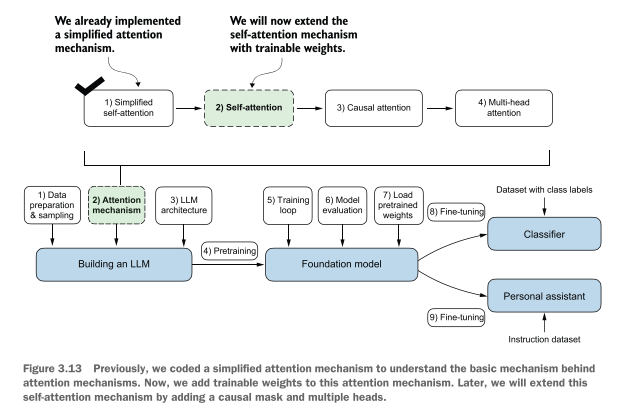

As illustrated in figure 3.13, the self-attention mechanism with trainable weights builds
on the previous concepts: we want to compute context vectors as weighted sums over
the input vectors specific to a certain input element. As you will see, there are only slight
differences compared to the basic self-attention mechanism we coded earlier.
The most notable difference is the introduction of weight matrices that are
updated during model training. These trainable weight matrices are crucial so that
the model (specifically, the attention module inside the model) can learn to produce
“good” context vectors.

### Computing the attention weights step by step

We will implement the self-attention mechanism step by step by introducing the
three trainable weight matrices Wq, Wk, and Wv. These three matrices are used to
project the embedded input tokens, x(i), into query, key, and value vectors, respectively.

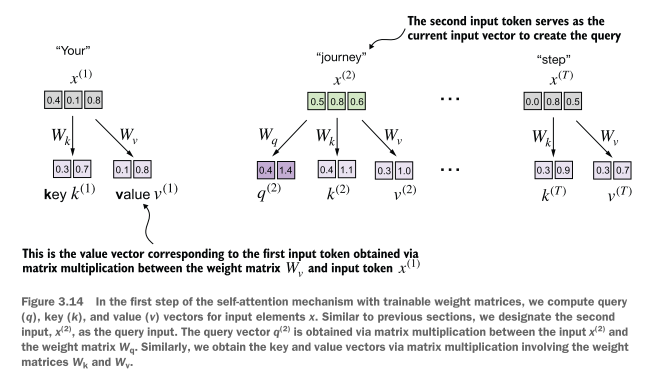

Earlier, we defined the second input element x(2) as the query when we computed the
simplified attention weights to compute the context vector z(2). Then we generalized
this to compute all context vectors z(1)
... z(T) for the six-word input sentence “Your
journey starts with one step.""

In [14]:
x_2 = inputs[1] # Second input element
d_in = inputs.shape[1] # The input embedding size, d=3
d_out = 2 # The output embedding size, d_out=2

Note that in GPT-like models, the input and output dimensions are usually the same,
but to better follow the computation, we’ll use different input (d_in=3) and output
(d_out=2) dimensions here.

We initialize the three weight matrices W_q, W_k and W_v

In [15]:
torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

We set requires_grad=False to reduce clutter in the outputs, but if we were to use
the weight matrices for model training, we would set requires_grad=True to update
these matrices during model training.

Next, we compute the query, key, and value vectors

In [16]:
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value = x_2 @ W_value

print(query_2)

tensor([0.4306, 1.4551])


>**Weight parameters vs. attention weights**
>
>In the weight matrices W, the term “weight” is short for “weight parameters,” the val-
ues of a neural network that are optimized during training. This is not to be confused
with the attention weights. As we already saw, attention weights determine the extent
to which a context vector depends on the different parts of the input (i.e., to what
extent the network focuses on different parts of the input).
In summary, weight parameters are the fundamental, learned coefficients that define
the network’s connections, while attention weights are dynamic, context-specific values.

Even though our temporary goal is only to compute the one context vector, z(2), we still
require the key and value vectors for all input elements as they are involved in computing the attention weights with respect to the query q(2).

We can obtain all keys and values via matrix multiplication

In [17]:
keys = inputs @ W_key
values = inputs @ W_value

print("Keys.shape: ", keys.shape)
print("values.shape: ", values.shape)

Keys.shape:  torch.Size([6, 2])
values.shape:  torch.Size([6, 2])


As we can tell from the outputs, we successfully projected the six input tokens from a
three-dimensional onto a two-dimensional embedding space

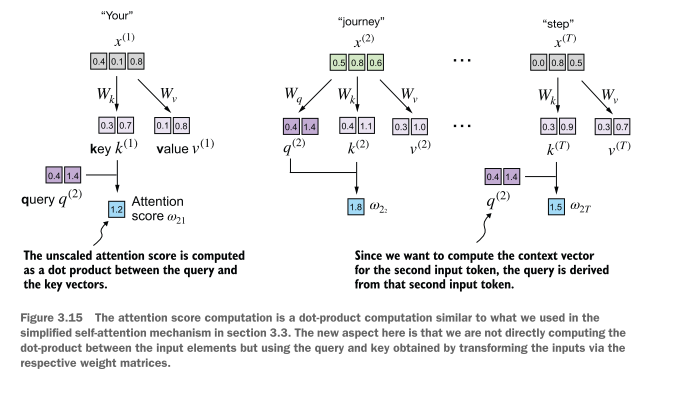

Lets compute the attention scores

In [18]:
keys_2 = keys[1]
attn_scores_22 = query_2.dot(keys_2)
print(attn_scores_22)

tensor(1.8524)


In [19]:
attn_scores_2 = query_2 @ keys.T
print(attn_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


Now, we want to go from the attention scores to the attention weights, as illustrated in
figure 3.16. We compute the attention weights by scaling the attention scores and
using the softmax function. However, now we scale the attention scores by dividing
them by the square root of the embedding dimension of the keys (taking the square
root is mathematically the same as exponentiating by 0.5)

In [20]:
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])


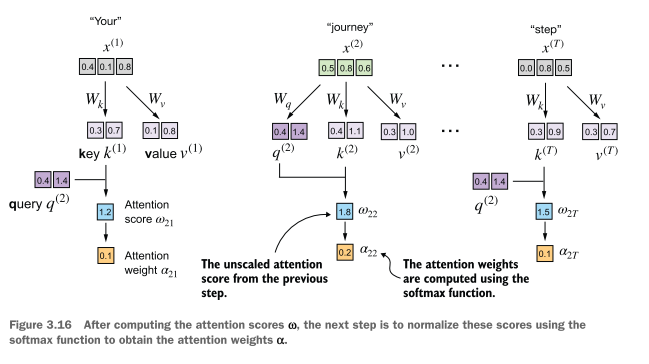

> The reason for the normalization by the embedding dimension size is to improve the
training performance by avoiding small gradients. For instance, when scaling up the
embedding dimension, which is typically greater than 1,000 for GPT-like LLMs, large
dot products can result in very small gradients during backpropagation due to the
softmax function applied to them. As dot products increase, the softmax function
behaves more like a step function, resulting in gradients nearing zero. These small
gradients can drastically slow down learning or cause training to stagnate.

Now, the final step is compute the context vectors

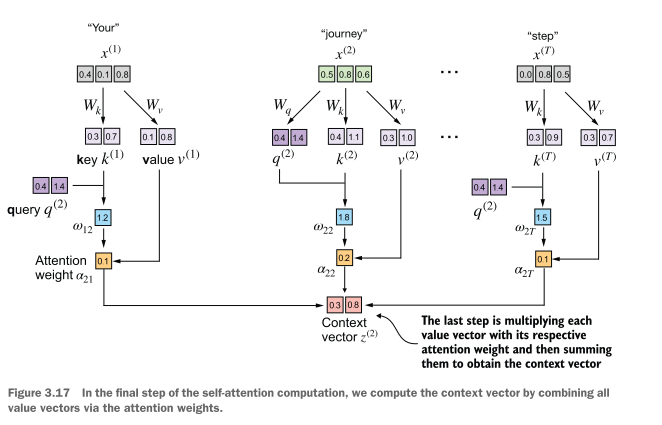

In [21]:
contextx_vec_2 = attn_weights_2 @ values
print(contextx_vec_2)

tensor([0.3061, 0.8210])


> **Why query, key, and value?**
>
> The terms “key,” “query,” and “value” in the context of attention mechanisms are
borrowed from the domain of information retrieval and databases, where similar con-
cepts are used to store, search, and retrieve information.
>
>A query is analogous to a search query in a database. It represents the current item
(e.g., a word or token in a sentence) the model focuses on or tries to understand.
The query is used to probe the other parts of the input sequence to determine how
much attention to pay to them.
>
>The key is like a database key used for indexing and searching. In the attention mech-
anism, each item in the input sequence (e.g., each word in a sentence) has an asso-
ciated key. These keys are used to match the query.
>
>The value in this context is similar to the value in a key-value pair in a database. It
represents the actual content or representation of the input items. Once the model
determines which keys (and thus which parts of the input) are most relevant to the
query (the current focus item), it retrieves the corresponding values.

### Implementing a compact selg-attention Python class

In [22]:
import torch.nn as nn

In [23]:
class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        attn_scores = queries @ keys.T #omega
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

The __init__ method initializes trainable weight matrices (W_query, W_key, and
W_value) for queries, keys, and values, each transforming the input dimension d_in to
an output dimension d_out.

During the forward pass, using the forward method, we compute the attention
scores (attn_scores) by multiplying queries and keys, normalizing these scores using
softmax. Finally, we create a context vector by weighting the values with these normal-
ized attention scores.

In [24]:
torch.manual_seed(123)

sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


As a quick check, notice that the second row ([0.3061, 0.8210]) matches the con-
tents of context_vec_2 in the previous section. Figure 3.18 summarizes the self-atten-
tion mechanism we just implemented.
Self-attention involves the trainable weight matrices Wq, Wk, and Wv. These matrices
transform input data into queries, keys, and values, respectively, which are crucial com-
ponents of the attention mechanism. As the model is exposed to more data during
training, it adjusts these trainable weights,

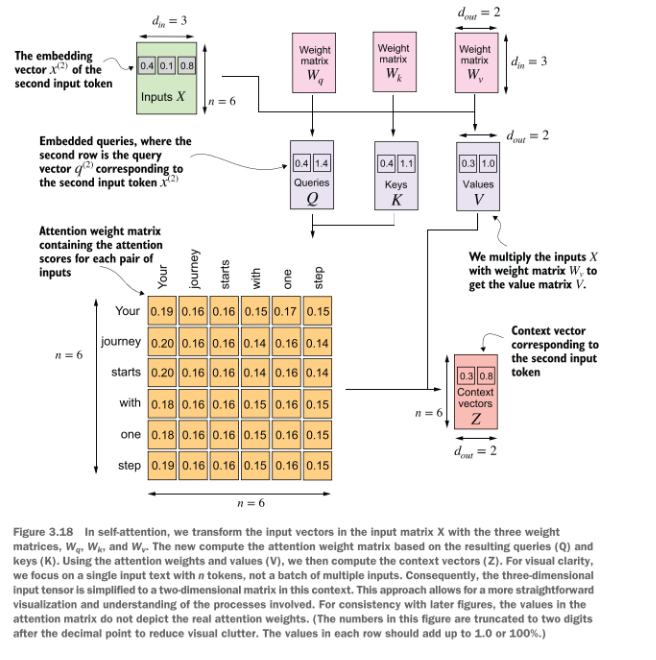

Instead of manually implementing nn.Parameter(torch.rand(...)) is that nn.Linear
has an optimized weight initialization scheme, contributing to more stable and
effective model training.

In [27]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias = qkv_bias)

    def forward(self, x): 
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

In [28]:
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


> Note that SelfAttention_v1 and SelfAttention_v2 give different outputs because
they use different initial weights for the weight matrices since nn.Linear uses a more
sophisticated weight initialization scheme

Next, we will make enhancements to the self-attention mechanism, focusing specifically
on incorporating causal and multi-head elements. The causal aspect involves modify-
ing the attention mechanism to prevent the model from accessing future information
in the sequence, which is crucial for tasks like language modeling, where each word
prediction should only depend on previous words.

The multi-head component involves splitting the attention mechanism into multi-
ple “heads.” Each head learns different aspects of the data, allowing the model to
simultaneously attend to information from different representation subspaces at dif-
ferent positions. This improves the model’s performance in complex tasks.

## Hiding future words with causal attention

For many LLM tasks, you will want the self-attention mechanism to consider only the
tokens that appear prior to the current position when predicting the next token in a
sequence. Causal attention, also known as masked attention, is a specialized form of self-
attention.

Now, we will modify the standard self-attention mechanism to create a causal
attention mechanism, which is essential for developing an LLM in the subsequent
chapters. To achieve this in GPT-like LLMs, for each token processed, we mask out
the future tokens, which come after the current token in the input text.

We mask out the attention weights above the diagonal, and we normalize the nonmasked attention weights such that the attention weights sum to 1 in
each row.

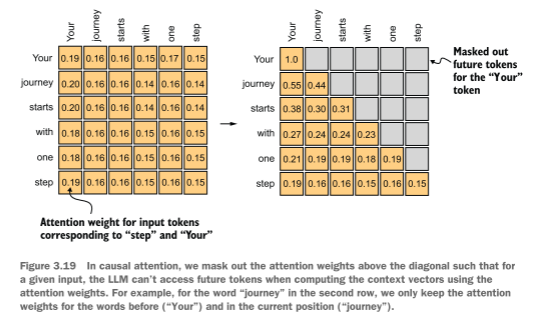

### Applying a causal attention mask

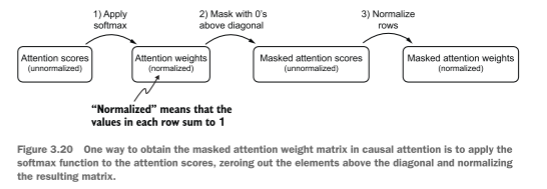

In the first step, we compute the attention weights using the softmax function as we
have done previously:

In [29]:
queries = sa_v2.W_query(inputs)
keys = sa_v2.W_key(inputs)
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


We can implement the second step using PyTorch’s tril function to create a mask
where the values above the diagonal are zero

In [30]:
context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


Now, we can multiply this mask with the attention weights to zero-out the values above
the diagonal:

In [32]:
masked_simple = attn_weights * mask_simple
print(masked_simple)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


The third step is to renormalize the attention weights to sum up to 1 again in each
row. We can achieve this by dividing each element in each row by the sum in each row

In [33]:
row_sums = masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


The result is an attention weight matrix where the attention weights above the diago-
nal are zeroed-out, and the rows sum to 1

> **Information leakage**
>
> When we apply a mask and then renormalize the attention weights, it might initially
appear that information from future tokens (which we intend to mask) could still influ-
ence the current token because their values are part of the softmax calculation.

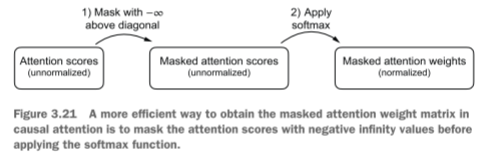

The softmax function converts its inputs into a probability distribution. When nega-
tive infinity values (-∞) are present in a row, the softmax function treats them as zero
probability. (Mathematically, this is because e–∞ approaches 0.)
We can implement this more efficient masking “trick” by creating a mask with 1s
above the diagonal and then replacing these 1s with negative infinity (-inf) values

In [34]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


In [35]:
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


We could now use the modified attention weights to compute the context vectors via
context_vec = attn_weights @ values, as in section 3.4. However, we will first cover
another minor tweak to the causal attention mechanism that is useful for reducing
overfitting when training LLMs.

### Masking additional attention weights with dropout

Dropout in deep learning is a technique where randomly selected hidden layer units
are ignored during training, effectively “dropping” them out. This method helps pre-
vent overfitting by ensuring that a model does not become overly reliant on any spe-
cific set of hidden layer units. It’s important to emphasize that dropout is only used
during training and is disabled afterward.

In the transformer architecture, including models like GPT, dropout in the atten-
tion mechanism is typically applied at two specific times: after calculating the atten-
tion weights or after applying the attention weights to the value vectors.

In the following code example, we use a dropout rate of 50%, which means mask-
ing out half of the attention weights. (When we train the GPT model in later chapters,
we will use a lower dropout rate, such as 0.1 or 0.2.) We apply PyTorch’s dropout
implementation first to a 6 × 6 tensor consisting of 1s for simplicity

In [37]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5) # Choose dropout of 50%
example = torch.ones(6, 6) # create matrix of 1s.
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


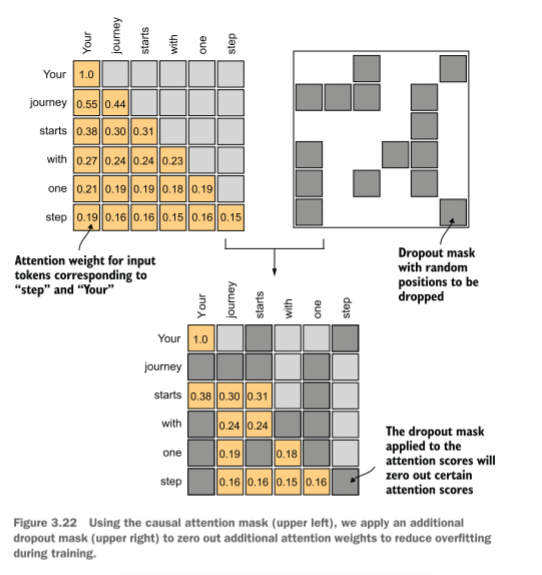

When applying dropout to an attention weight matrix with a rate of 50%, half of the
elements in the matrix are randomly set to zero. To compensate for the reduction in
active elements, the values of the remaining elements in the matrix are scaled up by a
factor of 1/0.5 = 2. This scaling is crucial to maintain the overall balance of the attention weights, ensuring that the average influence of the attention mechanism remains
consistent during both the training and inference phases.

In [38]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7599, 0.6194, 0.6206, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4921, 0.4925, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3966, 0.0000, 0.3775, 0.0000, 0.0000],
        [0.0000, 0.3327, 0.3331, 0.3084, 0.3331, 0.0000]],
       grad_fn=<MulBackward0>)


### Implementing a compact causal attention class

We will now incorporate the causal attention and dropout modifications into the
SelfAttention Python class we developed in section 3.4. This class will then serve as a
template for developing multi-head attention, which is the final attention class we will
implement.

In [39]:
batch = torch.stack((inputs, inputs), dim=0) 
print(batch.shape)

torch.Size([2, 6, 3])


This results in a three-dimensional tensor consisting of two input texts with six tokens
each, where each token is a three-dimensional embedding vector

In [40]:
class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            'mask', torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values
        return context_vec

While all added code lines should be familiar at this point, we now added a self
.register_buffer() call in the __init__ method. The use of register_buffer in
PyTorch is not strictly necessary for all use cases but offers several advantages here. For
instance, when we use the CausalAttention class in our LLM, buffers are automati-
cally moved to the appropriate device (CPU or GPU) along with our model, which will
be relevant when training our LLM.

In [41]:
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)

context_vecs.shape: torch.Size([2, 6, 2])


The resulting context vector is a three-dimensional tensor where each token is now
represented by a two-dimensional embedding

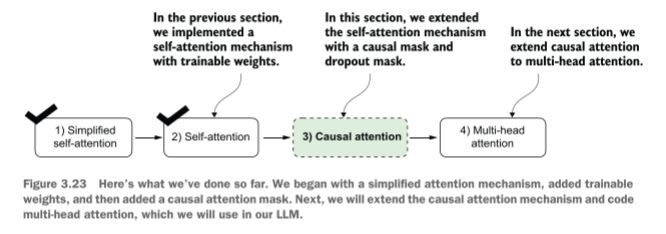

## Extending single-head attention to multi-head attention

The term “multi-head” refers to dividing the attention mechanism into multiple
“heads,” each operating independently. In this context, a single causal attention mod-
ule can be considered single-head attention, where there is only one set of attention
weights processing the input sequentially.

## Stacking multiple single-head attention layers

In practical terms, implementing multi-head attention involves creating multiple
instances of the self-attention mechanism (see figure 3.18), each with its own weights,
and then combining their outputs. Using multiple instances of the self-attention
mechanism can be computationally intensive, but it’s crucial for the kind of complex
pattern recognition that models like transformer-based LLMs are known for.

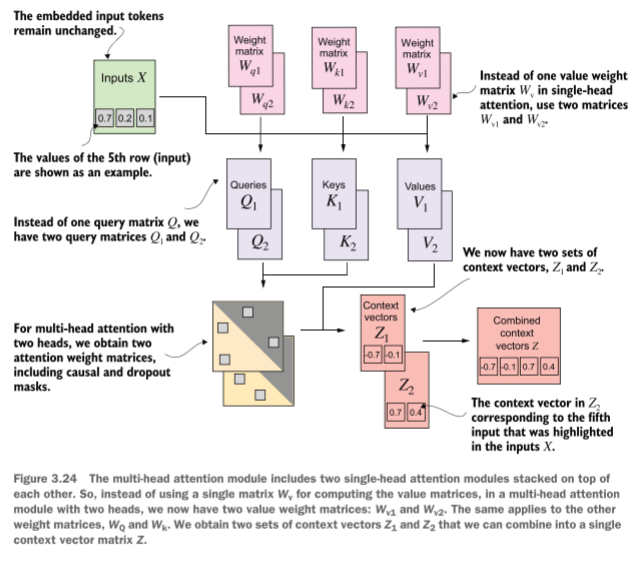

The main idea behind multi-head attention is to run the attention
mechanism multiple times (in parallel) with different, learned linear projections—the
results of multiplying the input data (like the query, key, and value vectors in attention
mechanisms) by a weight matrix. In code, we can achieve this by implementing a sim-
ple MultiHeadAttentionWrapper class that stacks multiple instances of our previously
implemented CausalAttention module.

In [42]:
class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(
                d_in, d_out, context_length, dropout, qkv_bias
            )
             for _ in range(num_heads)]
        )
    
    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

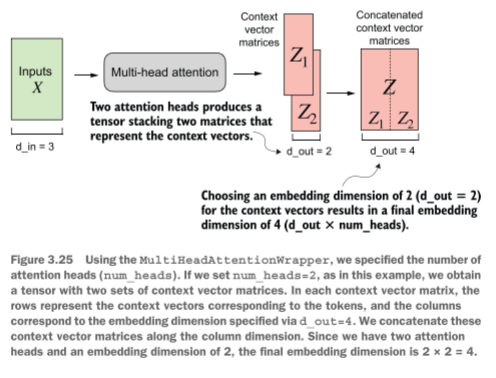

In [43]:
torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


>The first dimension of the resulting context_vecs tensor is 2 since we have two input
texts (the input texts are duplicated, which is why the context vectors are exactly the
same for those). The second dimension refers to the 6 tokens in each input. The third
dimension refers to the four-dimensional embedding of each token.

We can improve this
implementation by processing the heads in parallel. One way to achieve this is by com-
puting the outputs for all attention heads simultaneously via matrix multiplication.

### Implementing multi-head attention with weight splits

So far, we have created a MultiHeadAttentionWrapper to implement multi-head
attention by stacking multiple single-head attention modules. This was done by instan-
tiating and combining several CausalAttention objects.
Instead of maintaining two separate classes, MultiHeadAttentionWrapper and
CausalAttention, we can combine these concepts into a single MultiHeadAttention
class. Also, in addition to merging the MultiHeadAttentionWrapper with the Causal-
Attention code, we will make some other modifications to implement multi-head
attention more efficiently.

In [44]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)

        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        return context_vec

Even though the reshaping (.view) and transposing (.transpose) of tensors inside
the MultiHeadAttention class looks very mathematically complicated, the Multi-
HeadAttention class implements the same concept as the MultiHeadAttention-
Wrapper earlier.

On a big-picture level, in the previous MultiHeadAttentionWrapper, we stacked
multiple single-head attention layers that we combined into a multi-head attention
layer. The MultiHeadAttention class takes an integrated approach. It starts with a
multi-head layer and then internally splits this layer into individual attention heads.

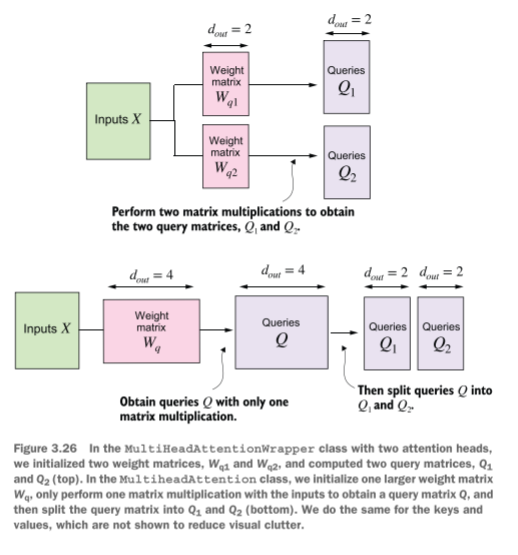

The tensors are then transposed to bring the num_heads dimension before the num_
tokens dimension, resulting in a shape of (b, num_heads, num_tokens, head_dim). This
transposition is crucial for correctly aligning the queries, keys, and values across the
different heads and performing batched matrix multiplications efficiently.

In [45]:
a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573],
                    [0.8993, 0.0390, 0.9268, 0.7388],
                    [0.7179, 0.7058, 0.9156, 0.4340]],
                   [[0.0772, 0.3565, 0.1479, 0.5331],
                    [0.4066, 0.2318, 0.4545, 0.9737],
                    [0.4606, 0.5159, 0.4220, 0.5786]]]])

In [46]:
print(a @ a.transpose(2, 3))

tensor([[[[1.3208, 1.1631, 1.2879],
          [1.1631, 2.2150, 1.8424],
          [1.2879, 1.8424, 2.0402]],

         [[0.4391, 0.7003, 0.5903],
          [0.7003, 1.3737, 1.0620],
          [0.5903, 1.0620, 0.9912]]]])


In [47]:
first_head = a[0, 0, :, :]
first_res = first_head @ first_head.T
print("First head:\n", first_res)
second_head = a[0, 1, :, :]
second_res = second_head @ second_head.T
print("\nSecond head:\n", second_res)

First head:
 tensor([[1.3208, 1.1631, 1.2879],
        [1.1631, 2.2150, 1.8424],
        [1.2879, 1.8424, 2.0402]])

Second head:
 tensor([[0.4391, 0.7003, 0.5903],
        [0.7003, 1.3737, 1.0620],
        [0.5903, 1.0620, 0.9912]])


Continuing with MultiHeadAttention, after computing the attention weights and con-
text vectors, the context vectors from all heads are transposed back to the shape (b,
num_tokens, num_heads, head_dim). These vectors are then reshaped (flattened) into
the shape (b, num_tokens, d_out), effectively combining the outputs from all heads.

In [48]:
batch_size, context_length, d_in = batch.shape
d_out = 2
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.1788, -0.6077],
         [-0.2099, -0.6397],
         [-0.2199, -0.6547],
         [-0.1932, -0.6522],
         [-0.1752, -0.6609],
         [-0.1716, -0.6540]],

        [[-0.1788, -0.6077],
         [-0.2099, -0.6397],
         [-0.2199, -0.6547],
         [-0.1932, -0.6522],
         [-0.1752, -0.6609],
         [-0.1716, -0.6540]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


>We have now implemented the MultiHeadAttention class that we will use when we
implement and train the LLM. Note that while the code is fully functional, I used
relatively small embedding sizes and numbers of attention heads to keep the outputs
readable.
For comparison, the smallest GPT-2 model (117 million parameters) has 12 atten-
tion heads and a context vector embedding size of 768. The largest GPT-2 model (1.5
billion parameters) has 25 attention heads and a context vector embedding size of
1,600. The embedding sizes of the token inputs and context embeddings are the same
in GPT models (d_in = d_out).